In [20]:
# ==========================================
# AI-POWERED FX RISK INTELLIGENCE PLATFORM
# Week 2 - Session 1
# Stationarity and Autocorrelation
# ==========================================

%pip install statsmodels

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

# Load dataset

df = pd.read_csv("../data/processed/cleaned_fx_data.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
pairs = ["GBPUSD_Close", "EURUSD_Close", "USDJPY_Close"]
print(df.head())
print("Dataset shape:", df.shape)


Note: you may need to restart the kernel to use updated packages.
        Date  GBPUSD_Close  GBPUSD_OHLC_Invalid  EURUSD_Close  \
0 2021-11-03      1.361739                False      1.157943   
1 2021-11-04      1.369488                 True      1.161575   
2 2021-11-05      1.350860                False      1.155535   
3 2021-11-08      1.349127                False      1.156885   
4 2021-11-09      1.356451                False      1.159152   

   EURUSD_OHLC_Invalid  USDJPY_Close  USDJPY_OHLC_Invalid  
0                False    113.961998                False  
1                False    114.070000                False  
2                False    113.836998                False  
3                False    113.474998                False  
4                False    113.253998                 True  
Dataset shape: (1300, 7)



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
# Calculate daily percentage returns

for pair in pairs:
    df[f"{pair}_Return"] = df[pair].pct_change(fill_method=None) * 100
print(df[["Date", "GBPUSD_Close_Return","EURUSD_Close_Return","USDJPY_Close_Return"]].head(10))

        Date  GBPUSD_Close_Return  EURUSD_Close_Return  USDJPY_Close_Return
0 2021-11-03                  NaN                  NaN                  NaN
1 2021-11-04             0.569023             0.313624             0.094770
2 2021-11-05            -1.360190            -0.519992            -0.204262
3 2021-11-08            -0.128293             0.116843            -0.317998
4 2021-11-09             0.542842             0.195906            -0.194757
5 2021-11-10            -0.033220             0.034781            -0.301972
6 2021-11-11            -1.086026            -0.945292             0.879443
7 2021-11-12            -0.344854            -0.305736             0.121154
8 2021-11-15             0.378359            -0.080088            -0.054362
9 2021-11-16            -0.064362            -0.656984             0.132479


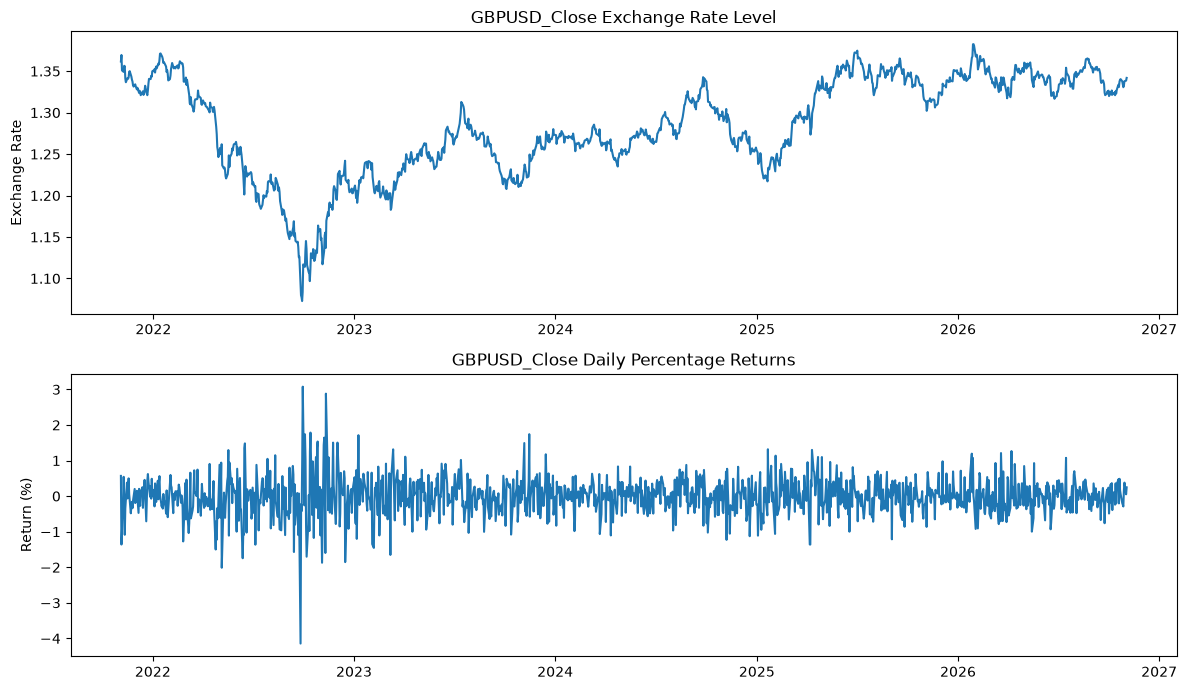

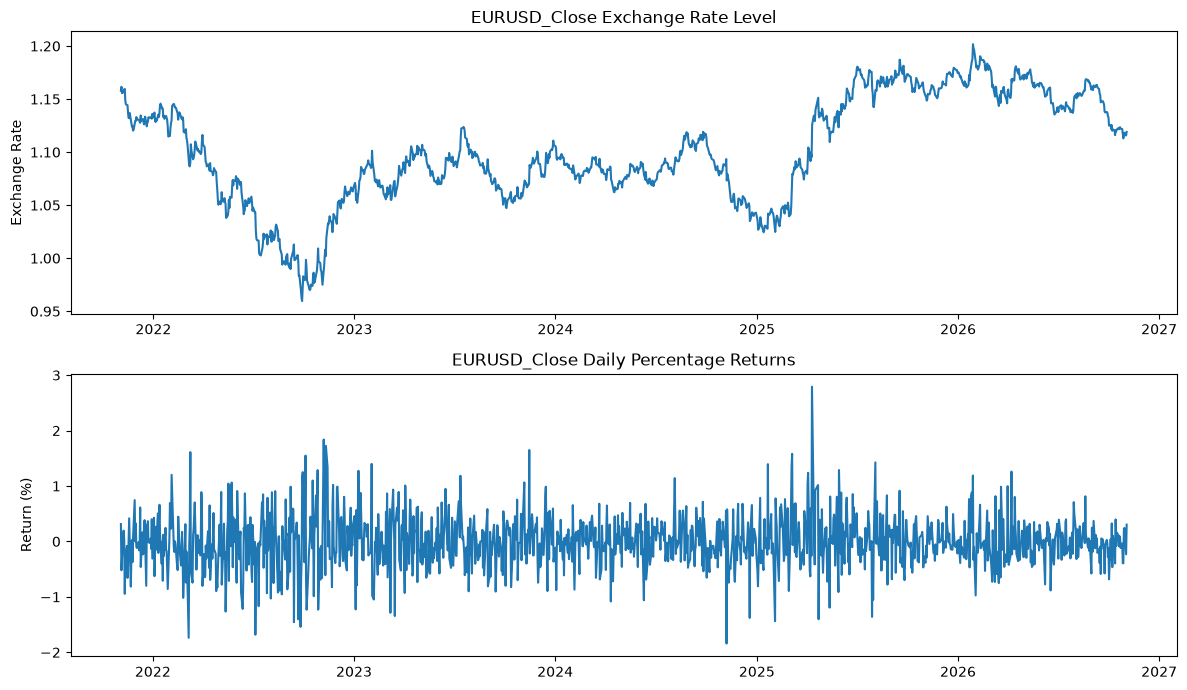

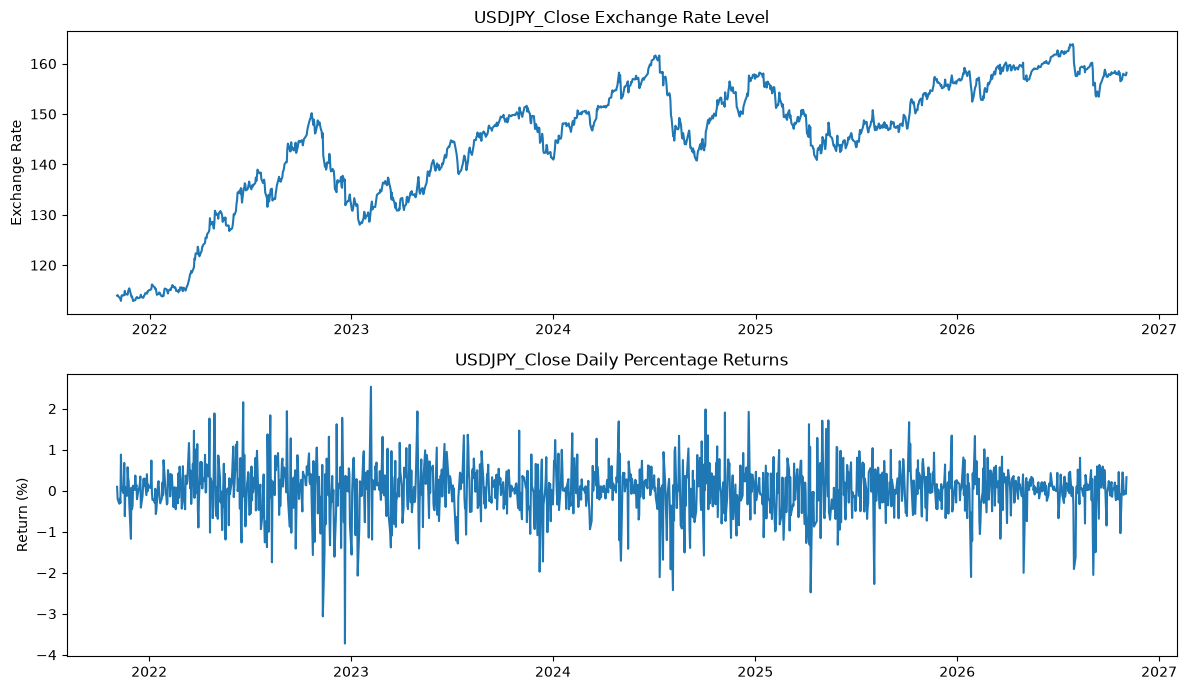

In [29]:
# Plot exchange rate levels and returns

for pair in pairs:

    fig, axes = plt.subplots(2, 1, figsize=(12, 7))

    # Exchange rate levels
    axes[0].plot(df["Date"], df[pair])
    axes[0].set_title(f"{pair} Exchange Rate Level")
    axes[0].set_ylabel("Exchange Rate")

    # Daily percentage returns
    axes[1].plot(df["Date"], df[f"{pair}_Return"])
    axes[1].set_title(f"{pair} Daily Percentage Returns")
    axes[1].set_ylabel("Return (%)")

    plt.tight_layout()
    plt.show()

In [32]:

# ADF stationarity test

for pair in pairs:

    returns = df[f"{pair}_Return"].dropna()

    result = adfuller(returns,regression="c",autolag="AIC")

    print(f"\n{pair} ADF TEST")

    print("ADF Statistic:", result[0])
    print("P-value:", result[1])
    print("Used Lags:", result[2])
    print("Observations:", result[3])
    print("Critical Values:", result[4])

    if result[1] < 0.05:

        print("Conclusion: Evidence of stationarity")

    else:

        print("Conclusion: Insufficient evidence of stationarity")


GBPUSD_Close ADF TEST
ADF Statistic: -16.395494294460015
P-value: 2.6689095111432037e-29
Used Lags: 5
Observations: 1293
Critical Values: {'1%': np.float64(-3.4354175403897727), '5%': np.float64(-2.8637778952086848), '10%': np.float64(-2.5679614713589562)}
Conclusion: Evidence of stationarity

EURUSD_Close ADF TEST
ADF Statistic: -12.904167903634805
P-value: 4.18689214974954e-24
Used Lags: 7
Observations: 1291
Critical Values: {'1%': np.float64(-3.4354254066484664), '5%': np.float64(-2.863781366113082), '10%': np.float64(-2.56796331977745)}
Conclusion: Evidence of stationarity

USDJPY_Close ADF TEST
ADF Statistic: -36.14633507619458
P-value: 0.0
Used Lags: 0
Observations: 1298
Critical Values: {'1%': np.float64(-3.4353979810093374), '5%': np.float64(-2.863769264797245), '10%': np.float64(-2.5679568752685773)}
Conclusion: Evidence of stationarity


C:\Users\alexb\AppData\Local\Temp\ipykernel_32600\1635729870.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(returns,regression="c",autolag="AIC")
C:\Users\alexb\AppData\Local\Temp\ipykernel_32600\1635729870.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(returns,regression="c",autolag="AIC")
C:\Users\alexb\AppData\Local\Temp\ip

In [35]:
# KPSS stationarity test

for pair in pairs:

    returns = df[f"{pair}_Return"].dropna()

    statistic, p_value, lags, critical_values = kpss(returns,regression="c",nlags="auto")

    print(f"\n{pair} KPSS TEST")

    print("KPSS Statistic:", statistic)
    print("P-value:", p_value)
    print("Used Lags:", lags)
    print("Critical Values:", critical_values)

    if p_value < 0.05:

        print("Conclusion: Evidence of non-stationarity")

    else:

        print("Conclusion: Evidence consistent with stationarity")


GBPUSD_Close KPSS TEST
KPSS Statistic: 0.15874426177975373
P-value: 0.1
Used Lags: 8
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Conclusion: Evidence consistent with stationarity

EURUSD_Close KPSS TEST
KPSS Statistic: 0.13896849613097623
P-value: 0.1
Used Lags: 4
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Conclusion: Evidence consistent with stationarity

USDJPY_Close KPSS TEST
KPSS Statistic: 0.17425375915762675
P-value: 0.1
Used Lags: 4
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Conclusion: Evidence consistent with stationarity


C:\Users\alexb\AppData\Local\Temp\ipykernel_32600\2161158842.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  statistic, p_value, lags, critical_values = kpss(returns,regression="c",nlags="auto")
C:\Users\alexb\AppData\Local\Temp\ipykernel_32600\2161158842.py:7: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value, lags, critical_values = kpss(returns,regression="c",nlags="auto")
C:\Users\alexb\AppData\Local\Temp\ipykernel_32600\2161158842.py:7: InterpolationWarning: The test statistic is outside of the ra

In [37]:
# Compare ADF and KPSS results

results = []

for pair in pairs:

    returns = df[f"{pair}_Return"].dropna()

    adf_result = adfuller(returns, regression="c")

    kpss_result = kpss(
        returns,
        regression="c",
        nlags="auto"
    )

    adf_stationary = adf_result[1] < 0.05

    kpss_stationary = kpss_result[1] >= 0.05

    if adf_stationary and kpss_stationary:

        conclusion = "Both tests support stationarity"

    elif not adf_stationary and not kpss_stationary:

        conclusion = "Both tests indicate non-stationarity"

    else:

        conclusion = "Conflicting test results"

    results.append({"Currency Pair": pair,"ADF Statistic": adf_result[0],"ADF P-value": adf_result[1],"KPSS Statistic": kpss_result[0],"KPSS P-value": kpss_result[1],"Conclusion": conclusion})

stationarity_results = pd.DataFrame(results)

print(stationarity_results.to_string(index=False))


Currency Pair  ADF Statistic  ADF P-value  KPSS Statistic  KPSS P-value                      Conclusion
 GBPUSD_Close     -16.395494 2.668910e-29        0.158744           0.1 Both tests support stationarity
 EURUSD_Close     -12.904168 4.186892e-24        0.138968           0.1 Both tests support stationarity
 USDJPY_Close     -36.146335 0.000000e+00        0.174254           0.1 Both tests support stationarity


C:\Users\alexb\AppData\Local\Temp\ipykernel_32600\3378495656.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(returns, regression="c")
C:\Users\alexb\AppData\Local\Temp\ipykernel_32600\3378495656.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
C:\Users\alexb\AppData\Local\Temp\ipykernel_32600\3378495656.py:11: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever 

In [39]:
# Autocorrelation analysis

for pair in pairs:

    returns = df[f"{pair}_Return"].dropna()

    print(f"\n{pair} AUTOCORRELATION")

    for lag in range(1, 21):

        correlation = returns.autocorr(lag=lag)

        print(f"Lag {lag}: {correlation:.4f}")


GBPUSD_Close AUTOCORRELATION
Lag 1: 0.0023
Lag 2: -0.0483
Lag 3: 0.0001
Lag 4: -0.0365
Lag 5: 0.0003
Lag 6: -0.0672
Lag 7: -0.0056
Lag 8: 0.0476
Lag 9: 0.0454
Lag 10: 0.0180
Lag 11: -0.0331
Lag 12: -0.0050
Lag 13: -0.0024
Lag 14: -0.0400
Lag 15: 0.0011
Lag 16: -0.0041
Lag 17: 0.0340
Lag 18: 0.0653
Lag 19: -0.0351
Lag 20: 0.0069

EURUSD_Close AUTOCORRELATION
Lag 1: 0.0094
Lag 2: -0.0341
Lag 3: -0.0323
Lag 4: 0.0158
Lag 5: 0.0228
Lag 6: -0.0619
Lag 7: -0.0458
Lag 8: 0.0652
Lag 9: 0.0009
Lag 10: -0.0036
Lag 11: -0.0246
Lag 12: -0.0154
Lag 13: 0.0152
Lag 14: 0.0202
Lag 15: -0.0265
Lag 16: 0.0523
Lag 17: 0.0373
Lag 18: -0.0104
Lag 19: -0.0265
Lag 20: -0.0000

USDJPY_Close AUTOCORRELATION
Lag 1: -0.0041
Lag 2: -0.0103
Lag 3: -0.0479
Lag 4: 0.0188
Lag 5: 0.0222
Lag 6: -0.0237
Lag 7: 0.0204
Lag 8: 0.0329
Lag 9: -0.0110
Lag 10: 0.0215
Lag 11: -0.0254
Lag 12: 0.0466
Lag 13: 0.0302
Lag 14: 0.0526
Lag 15: -0.0119
Lag 16: -0.0290
Lag 17: 0.0045
Lag 18: 0.0109
Lag 19: -0.0176
Lag 20: -0.0496


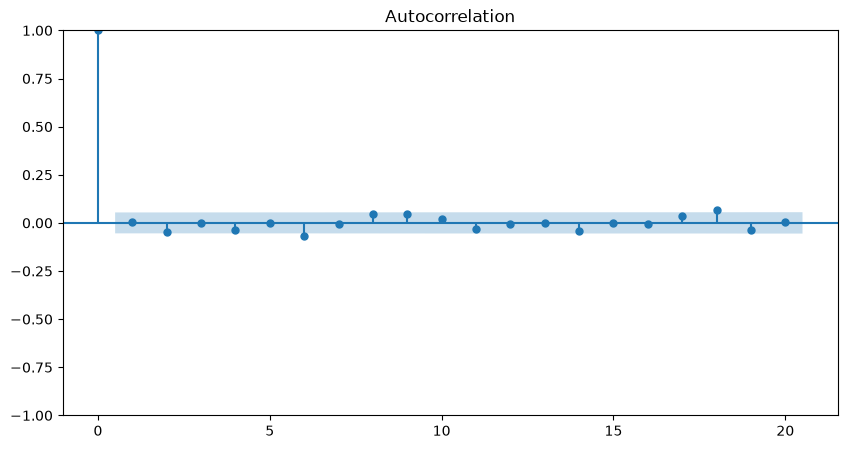

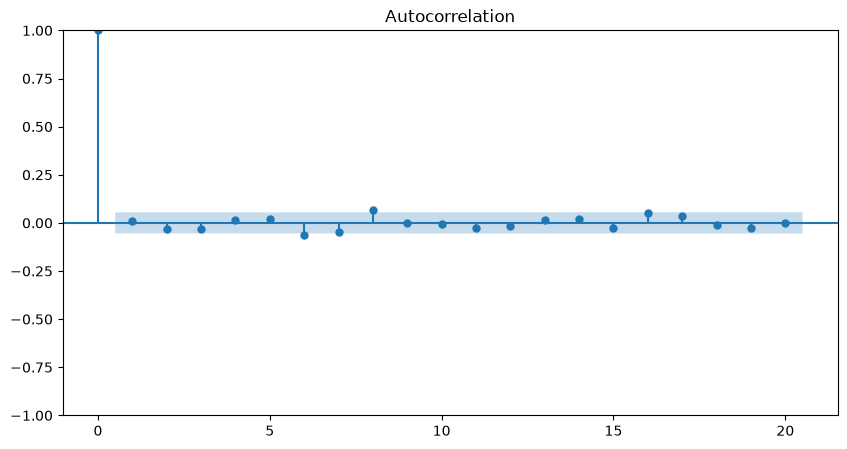

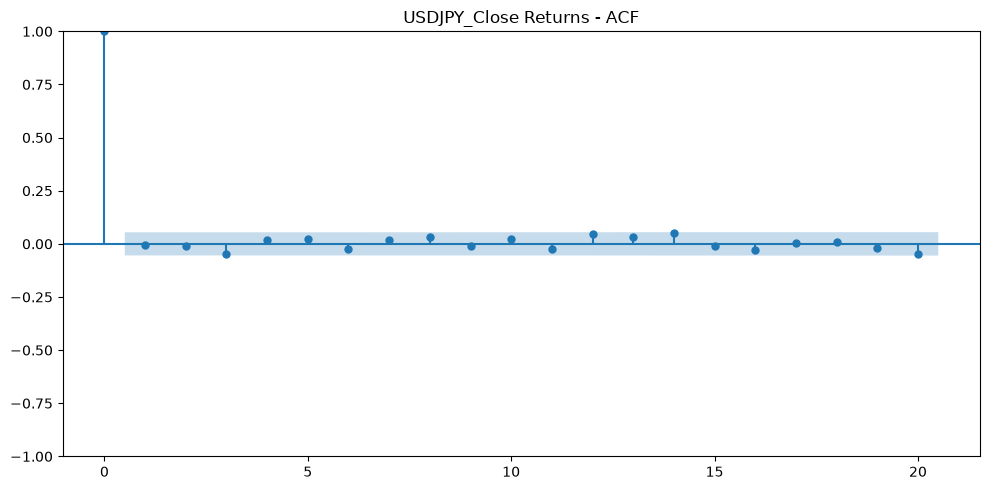

In [40]:
# ACF plots - Daily returns

for pair in pairs:

    returns = df[f"{pair}_Return"].dropna()

    fig, ax = plt.subplots(figsize=(10,5))

    plot_acf(returns, lags=20, alpha=0.05, ax=ax)
    
ax.set_title(f"{pair} Returns - ACF")

plt.tight_layout()
plt.show()
